In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from xgboost import XGBClassifier

import pickle

%matplotlib inline

In [62]:
red = pd.read_csv('/content/winequality-red.csv', sep=';')
white = pd.read_csv('/content/winequality-white.csv', sep=';')

red['wine_type'] = 'red'
white['wine_type'] = 'white'

# merging the two datasets
df = pd.concat([red, white], ignore_index=True)
df.shape

(6497, 13)

In [63]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [64]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
df.columns

Index(['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar',
       'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density',
       'ph', 'sulphates', 'alcohol', 'quality', 'wine_type'],
      dtype='object')

In [65]:
df.isnull().sum()

,0
fixed_acidity,0
volatile_acidity,0
citric_acid,0
residual_sugar,0
chlorides,0
free_sulfur_dioxide,0
total_sulfur_dioxide,0
density,0
ph,0
sulphates,0


In [66]:
df.describe()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [67]:
print('Rows before:', len(df))
print('Duplicates:', df.duplicated().sum())

# drop the duplicate values
df = df.drop_duplicates().reset_index(drop=True)
print('Rows after:', len(df))

Rows before: 6497
Duplicates: 1177
Rows after: 5320


In [68]:
df['good'] = (df.quality >= 7).astype(int)
df.good.value_counts(normalize=True)

,proportion
good,
0,0.810338
1,0.189662


In [69]:
categorical_features = ['wine_type']
numerical_features = [col for col in df.columns
                      if col not in categorical_features + ['quality', 'good']]

print('Numerical:', numerical_features)
print('Categorical:', categorical_features)

Numerical: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates', 'alcohol']
Categorical: ['wine_type']


# EDA

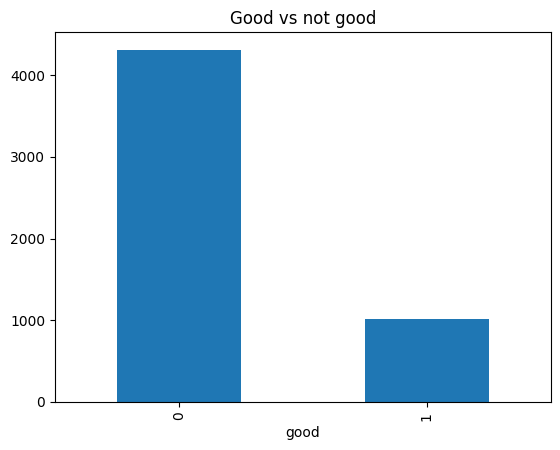

good,0,1
wine_type,,
red,0.864606,0.135394
white,0.791719,0.208281


In [70]:
df.good.value_counts().plot(kind='bar')
plt.title('Good vs not good')
plt.show()

pd.crosstab(df.wine_type, df.good, normalize='index')

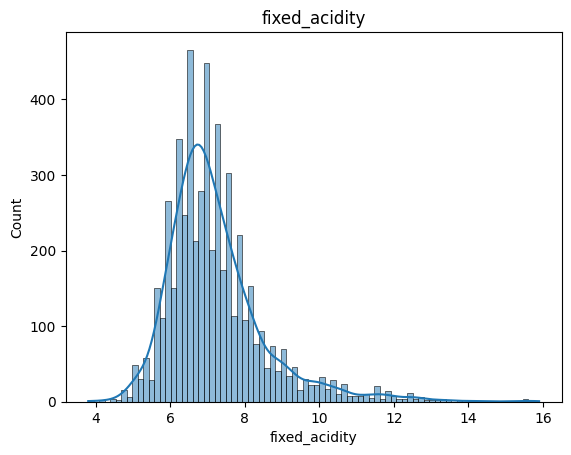

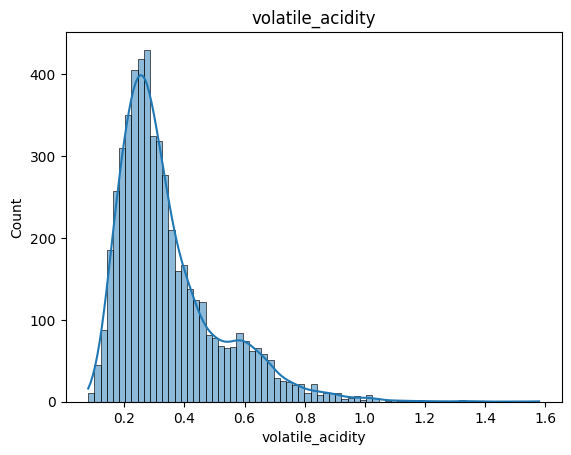

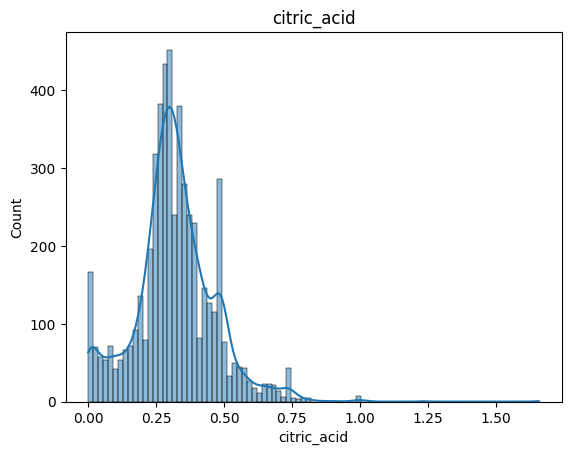

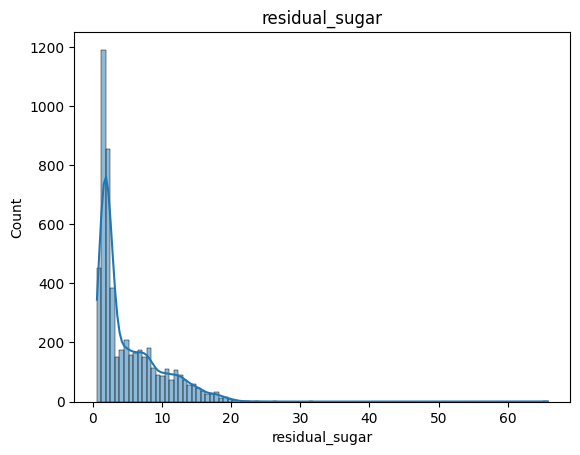

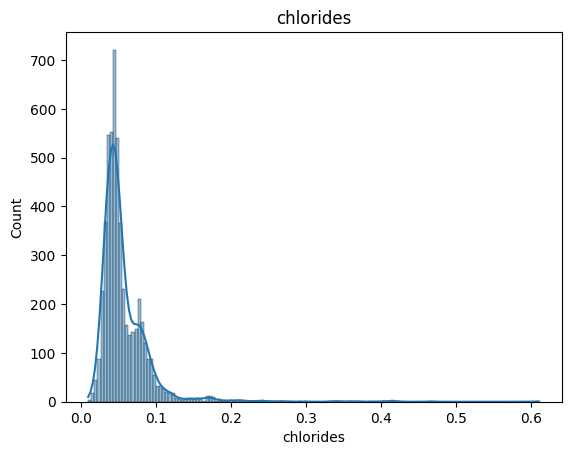

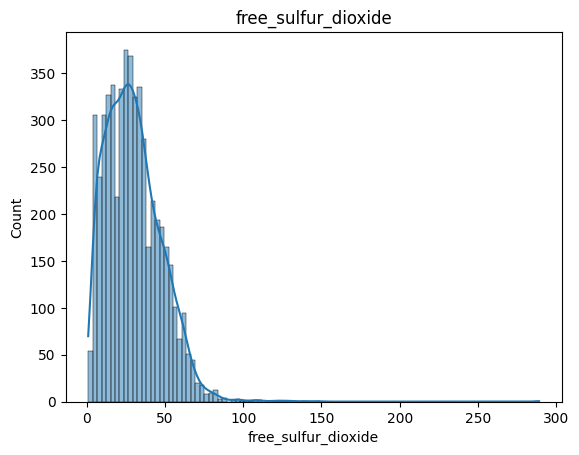

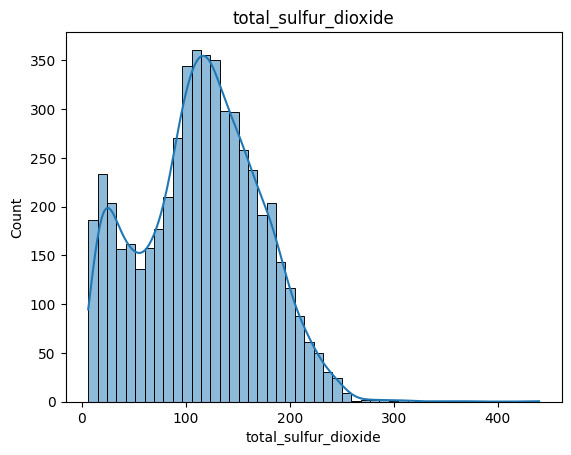

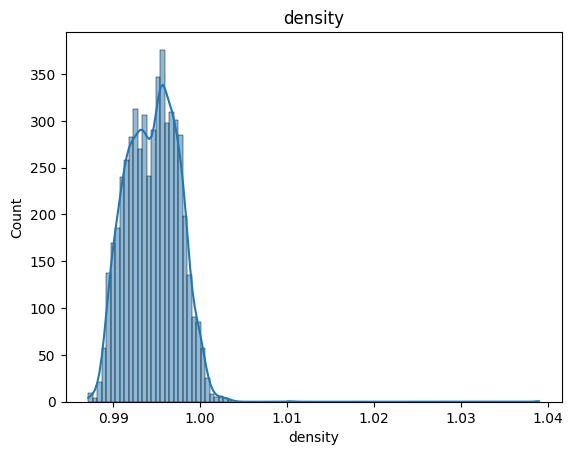

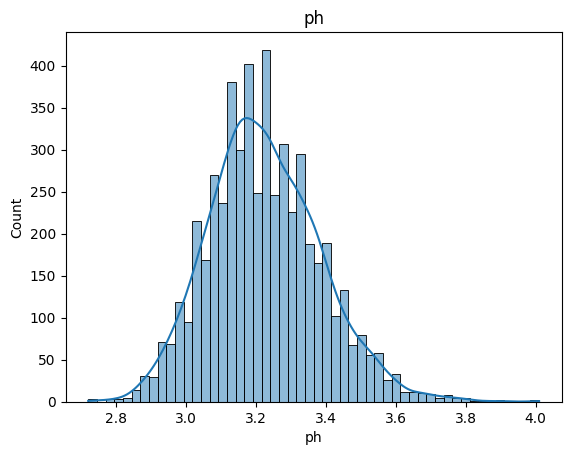

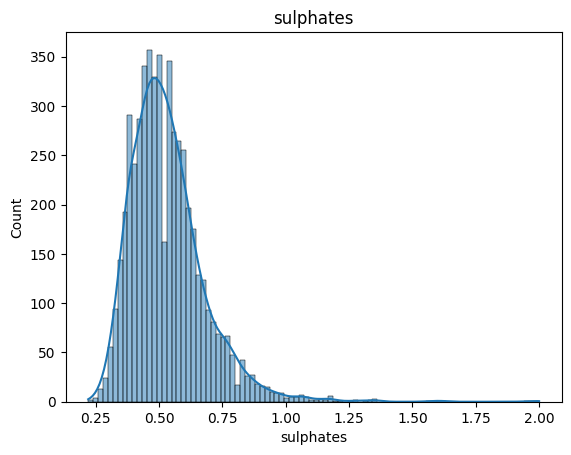

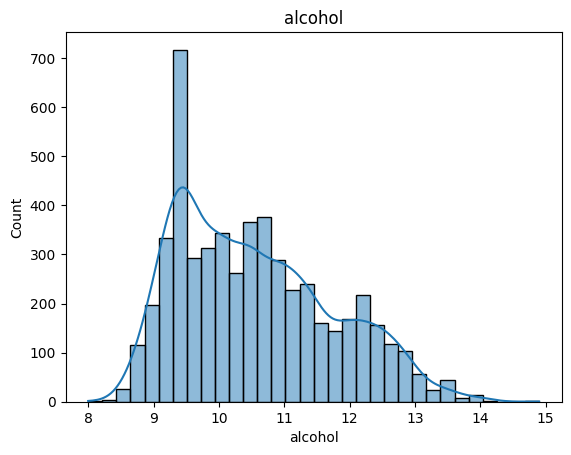

In [71]:
for col in numerical_features:
    sns.histplot(df[col], kde=True)
    plt.title(col)
    plt.show()

In [72]:
df.groupby('good')[numerical_features].mean().T

good,0,1
fixed_acidity,7.246996,7.079237
volatile_acidity,0.355879,0.293930
citric_acid,0.314175,0.336947
residual_sugar,5.233229,4.259118
chlorides,0.059561,0.044421
free_sulfur_dioxide,29.939109,30.453419
total_sulfur_dioxide,115.957550,106.211100
density,0.994958,0.992727
ph,3.220914,3.240684
sulphates,0.530694,0.544737


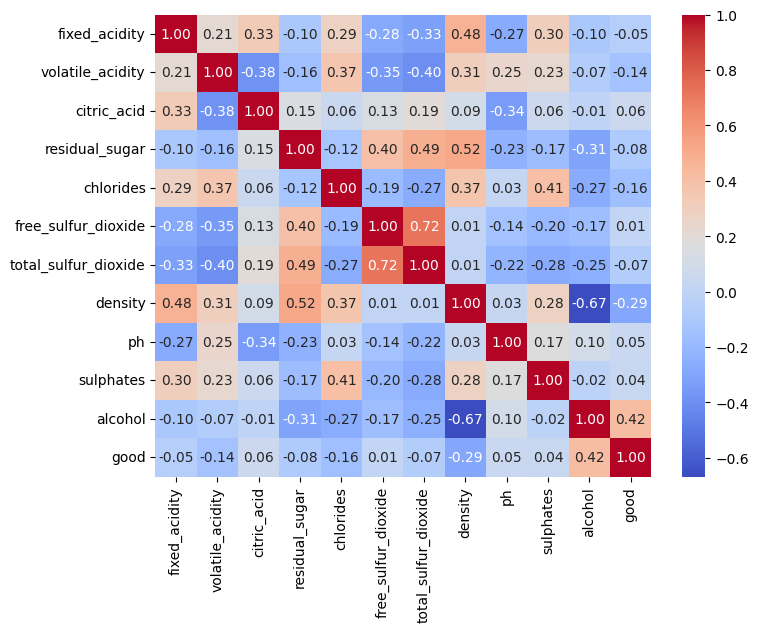

In [73]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[numerical_features + ['good']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [74]:
df.groupby(['wine_type', 'good'])[numerical_features].mean().T

wine_type                   red                  white            
good                          0          1           0           1
fixed_acidity          8.230809   8.820109    6.878380    6.690970
volatile_acidity       0.548834   0.405870    0.283583    0.268964
citric_acid            0.256587   0.372880    0.335753    0.328933
residual_sugar         2.495149   2.703804    6.259136    4.606000
chlorides              0.090014   0.076049    0.048151    0.037367
free_sulfur_dioxide   16.194043  13.972826   35.089126   34.129091
total_sulfur_dioxide  48.621702  35.358696  141.187022  122.013333
density                0.996826   0.995963    0.994259    0.992006
ph                     3.313106   3.288587    3.186371    3.230000
sulphates              0.645098   0.745598    0.487828    0.499939
alcohol               10.256851  11.552808   10.329346   11.577717

# Setting up validation framework

In [75]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df.good)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42, stratify=df_full_train.good)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

len(df_train), len(df_val), len(df_test)

(3192, 1064, 1064)

In [76]:
print(df_train.good.mean(), df_val.good.mean(), df_test.good.mean())

0.18953634085213034 0.18984962406015038 0.18984962406015038


In [77]:
y_train = df_train.good.values
y_val = df_val.good.values
y_test = df_test.good.values

for d in [df_train, df_val, df_test]:
    del d['good']
    del d['quality']

In [78]:
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')
test_dicts = df_test.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

dv.get_feature_names_out()

array(['alcohol', 'chlorides', 'citric_acid', 'density', 'fixed_acidity',
       'free_sulfur_dioxide', 'ph', 'residual_sugar', 'sulphates',
       'total_sulfur_dioxide', 'volatile_acidity', 'wine_type=red',
       'wine_type=white'], dtype=object)

In [79]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score, f1_score

In [80]:
def evaluate(model, X, y, threshold=0.5):
    y_prob = model.predict_proba(X)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)

    return {
        'roc_auc': roc_auc_score(y, y_prob),
        'pr_auc': average_precision_score(y, y_prob),
        'precision': precision_score(y, y_pred, zero_division=0),
        'recall': recall_score(y, y_pred),
        'f1': f1_score(y, y_pred),
    }

# A. Logistic regression model

In [81]:
lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
lr.fit(X_train, y_train)

results = []
results.append({'model': 'LogReg', **evaluate(lr, X_val, y_val)})
pd.DataFrame(results).round(3)

,model,roc_auc,pr_auc,precision,recall,f1
0,LogReg,0.826,0.515,0.6,0.342,0.435


In [82]:
lr_bal = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
)
lr_bal.fit(X_train, y_train)

results.append({'model': 'LogReg (balanced)', **evaluate(lr_bal, X_val, y_val)})
pd.DataFrame(results).round(3)

,model,roc_auc,pr_auc,precision,recall,f1
0,LogReg,0.826,0.515,0.600,0.342,0.435
1,LogReg (balanced),0.825,0.512,0.399,0.752,0.521


In [83]:
scores = []

for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=C, max_iter=1000, random_state=42)
    )
    model.fit(X_train, y_train)
    auc = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
    scores.append((C, auc))
    print(f'C={C}: Validation AUC = {auc:.3f}')

C=0.001: Validation AUC = 0.811
C=0.01: Validation AUC = 0.823
C=0.1: Validation AUC = 0.826
C=1: Validation AUC = 0.826
C=10: Validation AUC = 0.826
C=100: Validation AUC = 0.826


# B. Random forest Model classifier

In [84]:
scores = []

for n in range(10, 201, 10):
    rf = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    scores.append((n, auc))

df_scores = pd.DataFrame(scores, columns=['n_estimators', 'auc'])
df_scores

,n_estimators,auc
0,10,0.770928
1,20,0.807315
2,30,0.815637
3,40,0.828180
4,50,0.834259
5,60,0.837791
6,70,0.838247
7,80,0.840562
8,90,0.841487
9,100,0.842885


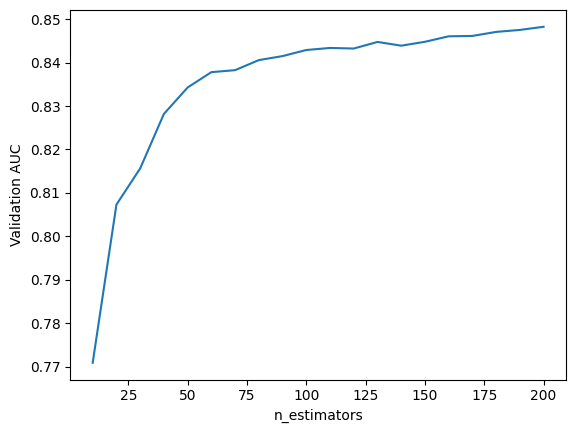

In [85]:
plt.plot(df_scores.n_estimators, df_scores.auc)
plt.xlabel('n_estimators')
plt.ylabel('Validation AUC')
plt.show()

In [86]:
scores = []

for d in [5, 10, 15, None]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=d,
                                    random_state=42, n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, n, auc))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'n_estimators', 'auc'])

In [87]:
df_scores

,max_depth,n_estimators,auc
0,5.0,10,0.816826
1,5.0,20,0.822176
2,5.0,30,0.823448
3,5.0,40,0.827158
4,5.0,50,0.825239
...,...,...,...
75,NaN,160,0.846038
76,NaN,170,0.846124
77,NaN,180,0.847049
78,NaN,190,0.847505


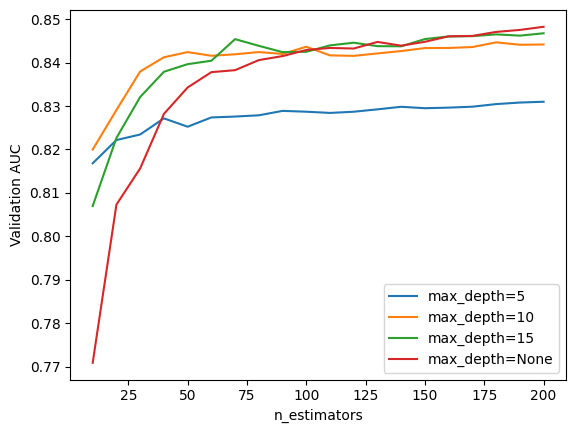

In [88]:
for d in [5, 10, 15, None]:
    df_subset = df_scores[df_scores.max_depth.isna()] if d is None \
                else df_scores[df_scores.max_depth == d]
    plt.plot(df_subset.n_estimators, df_subset.auc, label=f'max_depth={d}')

plt.legend()
plt.xlabel('n_estimators')
plt.ylabel('Validation AUC')
plt.show()

In [89]:
max_depth = 15

scores = []

for s in [1, 3, 5, 10, 20]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=max_depth,
                                    min_samples_leaf=s,
                                    random_state=42, n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((s, n, auc))

df_scores = pd.DataFrame(scores, columns=['min_samples_leaf', 'n_estimators', 'auc'])

In [90]:
df_scores

,min_samples_leaf,n_estimators,auc
0,1,10,0.807002
1,1,20,0.822652
2,1,30,0.832065
3,1,40,0.837874
4,1,50,0.839629
...,...,...,...
95,20,160,0.842365
96,20,170,0.842474
97,20,180,0.842807
98,20,190,0.842716


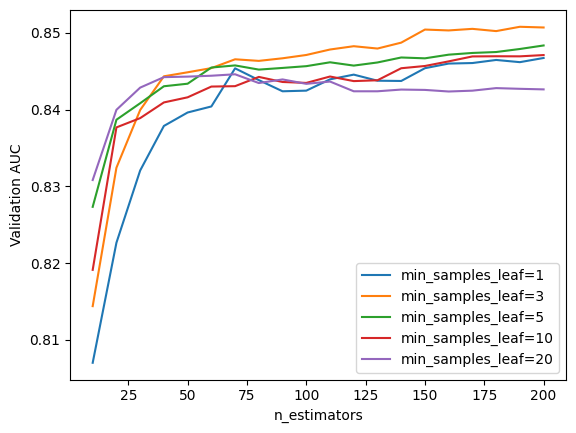

In [91]:
for s in [1, 3, 5, 10, 20]:
    df_subset = df_scores[df_scores.min_samples_leaf == s]
    plt.plot(df_subset.n_estimators, df_subset.auc, label=f'min_samples_leaf={s}')

plt.legend()
plt.xlabel('n_estimators')
plt.ylabel('Validation AUC')
plt.show()

Random forest parameter tunning

In [92]:
from sklearn.model_selection import GridSearchCV

params = {
    'n_estimators': [100, 150, 200],
    'max_depth': [10, 15, None],
    'min_samples_leaf': [1, 2, 3, 5],
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=params,
    scoring='roc_auc',
    cv=5,
    verbose=1,
)
grid_search.fit(X_train, y_train)

print('Best params:', grid_search.best_params_)
print('Best CV AUC:', round(grid_search.best_score_, 4))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}
Best CV AUC: 0.8425


In [93]:
best_rf = grid_search.best_estimator_

results.append({'model': 'RandomForest', **evaluate(best_rf, X_val, y_val)})
pd.DataFrame(results).round(3)

,model,roc_auc,pr_auc,precision,recall,f1
0,LogReg,0.826,0.515,0.600,0.342,0.435
1,LogReg (balanced),0.825,0.512,0.399,0.752,0.521
2,RandomForest,0.849,0.568,0.670,0.302,0.416


# C. XGBoost Model

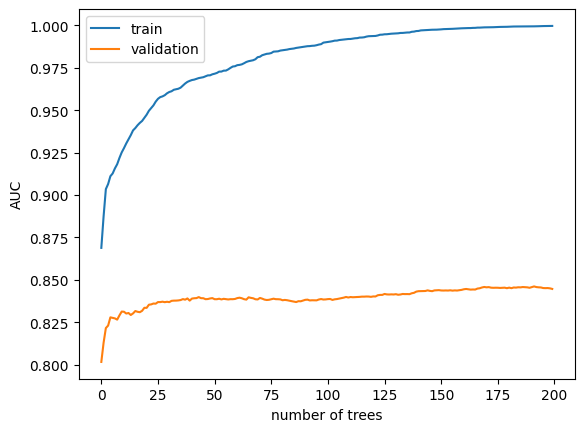

In [94]:
xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1,
)

xgb.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False,
)

evals = xgb.evals_result()
plt.plot(evals['validation_0']['auc'], label='train')
plt.plot(evals['validation_1']['auc'], label='validation')
plt.xlabel('number of trees')
plt.ylabel('AUC')
plt.legend()
plt.show()

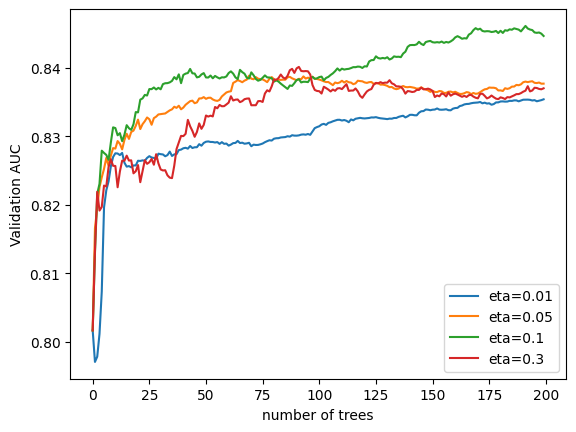

eta=0.01: best AUC = 0.8354 at tree 200
eta=0.05: best AUC = 0.8389 at tree 70
eta=0.1: best AUC = 0.8461 at tree 192
eta=0.3: best AUC = 0.8402 at tree 92


In [95]:
scores = {}

for eta in [0.01, 0.05, 0.1, 0.3]:
    model = XGBClassifier(
        n_estimators=200,
        learning_rate=eta,
        max_depth=6,
        eval_metric='auc',
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X_train, y_train,
              eval_set=[(X_val, y_val)], verbose=False)
    scores[eta] = model.evals_result()['validation_0']['auc']

for eta, aucs in scores.items():
    plt.plot(aucs, label=f'eta={eta}')

plt.xlabel('number of trees')
plt.ylabel('Validation AUC')
plt.legend()
plt.show()

for eta, aucs in scores.items():
    print(f'eta={eta}: best AUC = {max(aucs):.4f} at tree {int(np.argmax(aucs)) + 1}')

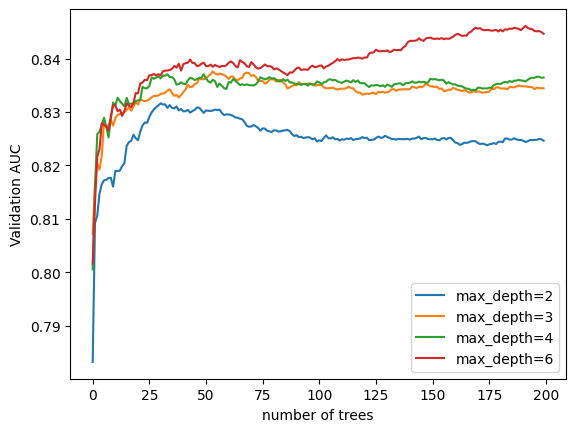

max_depth=2: best AUC = 0.8316 at tree 31, AUC at tree 200 = 0.8246
max_depth=3: best AUC = 0.8376 at tree 54, AUC at tree 200 = 0.8345
max_depth=4: best AUC = 0.8371 at tree 50, AUC at tree 200 = 0.8365
max_depth=6: best AUC = 0.8461 at tree 192, AUC at tree 200 = 0.8447


In [96]:
scores = {}

for d in [2, 3, 4, 6]:
    model = XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=d,
        eval_metric='auc',
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X_train, y_train,
              eval_set=[(X_val, y_val)], verbose=False)
    scores[d] = model.evals_result()['validation_0']['auc']

for d, aucs in scores.items():
    plt.plot(aucs, label=f'max_depth={d}')

plt.xlabel('number of trees')
plt.ylabel('Validation AUC')
plt.legend()
plt.show()

for d, aucs in scores.items():
    print(f'max_depth={d}: best AUC = {max(aucs):.4f} at tree {int(np.argmax(aucs)) + 1}, '
          f'AUC at tree 200 = {aucs[199]:.4f}')

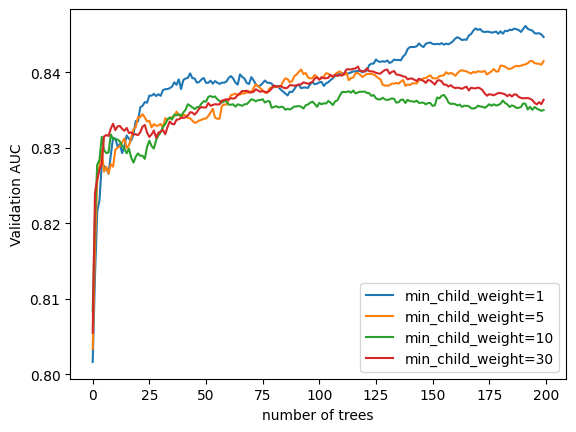

min_child_weight=1: best AUC = 0.8461, AUC at tree 200 = 0.8447
min_child_weight=5: best AUC = 0.8415, AUC at tree 200 = 0.8415
min_child_weight=10: best AUC = 0.8376, AUC at tree 200 = 0.8350
min_child_weight=30: best AUC = 0.8408, AUC at tree 200 = 0.8364


In [97]:
max_depth = 6   # change this to the best depth from Cell 30

scores = {}

for w in [1, 5, 10, 30]:
    model = XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=max_depth,
        min_child_weight=w,
        eval_metric='auc',
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X_train, y_train,
              eval_set=[(X_val, y_val)], verbose=False)
    scores[w] = model.evals_result()['validation_0']['auc']

for w, aucs in scores.items():
    plt.plot(aucs, label=f'min_child_weight={w}')

plt.xlabel('number of trees')
plt.ylabel('Validation AUC')
plt.legend()
plt.show()

for w, aucs in scores.items():
    print(f'min_child_weight={w}: best AUC = {max(aucs):.4f}, AUC at tree 200 = {aucs[199]:.4f}')

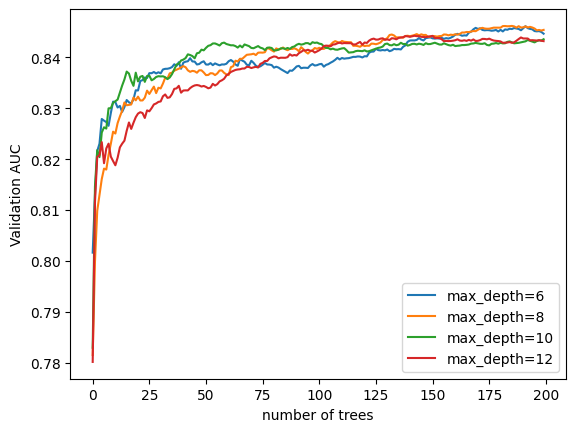

max_depth=6: best AUC = 0.8461, AUC at tree 200 = 0.8447
max_depth=8: best AUC = 0.8462, AUC at tree 200 = 0.8454
max_depth=10: best AUC = 0.8436, AUC at tree 200 = 0.8436
max_depth=12: best AUC = 0.8443, AUC at tree 200 = 0.8432


In [98]:
scores = {}

for d in [6, 8, 10, 12]:
    model = XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=d,
        min_child_weight=1,
        eval_metric='auc',
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X_train, y_train,
              eval_set=[(X_val, y_val)], verbose=False)
    scores[d] = model.evals_result()['validation_0']['auc']

for d, aucs in scores.items():
    plt.plot(aucs, label=f'max_depth={d}')

plt.xlabel('number of trees')
plt.ylabel('Validation AUC')
plt.legend()
plt.show()

for d, aucs in scores.items():
    print(f'max_depth={d}: best AUC = {max(aucs):.4f}, AUC at tree 200 = {aucs[-1]:.4f}')

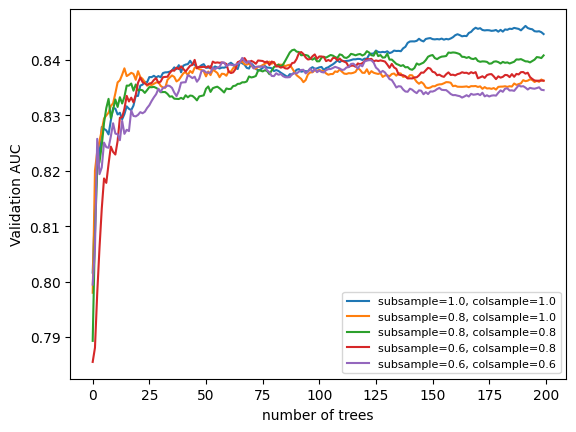

subsample=1.0, colsample=1.0: best = 0.8461, at tree 200 = 0.8447
subsample=0.8, colsample=1.0: best = 0.8398, at tree 200 = 0.8363
subsample=0.8, colsample=0.8: best = 0.8419, at tree 200 = 0.8408
subsample=0.6, colsample=0.8: best = 0.8414, at tree 200 = 0.8363
subsample=0.6, colsample=0.6: best = 0.8404, at tree 200 = 0.8346


In [99]:
max_depth = 6

configs = [(1.0, 1.0), (0.8, 1.0), (0.8, 0.8), (0.6, 0.8), (0.6, 0.6)]
scores = {}

for sub, col in configs:
    model = XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=max_depth,
        min_child_weight=1,
        subsample=sub,
        colsample_bytree=col,
        eval_metric='auc',
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X_train, y_train,
              eval_set=[(X_val, y_val)], verbose=False)
    scores[(sub, col)] = model.evals_result()['validation_0']['auc']

for (sub, col), aucs in scores.items():
    plt.plot(aucs, label=f'subsample={sub}, colsample={col}')

plt.xlabel('number of trees')
plt.ylabel('Validation AUC')
plt.legend(fontsize=8)
plt.show()

for (sub, col), aucs in scores.items():
    print(f'subsample={sub}, colsample={col}: best = {max(aucs):.4f}, at tree 200 = {aucs[-1]:.4f}')

In [100]:
xgb_final = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    min_child_weight=1,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1,
)
xgb_final.fit(X_train, y_train)

results.append({'model': 'XGBoost', **evaluate(xgb_final, X_val, y_val)})
pd.DataFrame(results).round(3)

,model,roc_auc,pr_auc,precision,recall,f1
0,LogReg,0.826,0.515,0.600,0.342,0.435
1,LogReg (balanced),0.825,0.512,0.399,0.752,0.521
2,RandomForest,0.849,0.568,0.670,0.302,0.416
3,XGBoost,0.845,0.566,0.632,0.426,0.509


K-FOld Cross validation

In [101]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'LogReg': lr,
    'RandomForest': best_rf,
    'XGBoost': xgb_final,
}

cv_rows = []
for name, model in models.items():
    out = cross_validate(model, X_train, y_train, cv=cv,
                         scoring={'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'})
    cv_rows.append({
        'model': name,
        'roc_auc_mean': out['test_roc_auc'].mean(),
        'roc_auc_std': out['test_roc_auc'].std(),
        'pr_auc_mean': out['test_pr_auc'].mean(),
        'pr_auc_std': out['test_pr_auc'].std(),
    })

pd.DataFrame(cv_rows).round(3)

,model,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
0,LogReg,0.834,0.004,0.529,0.024
1,RandomForest,0.840,0.010,0.557,0.020
2,XGBoost,0.830,0.010,0.534,0.011


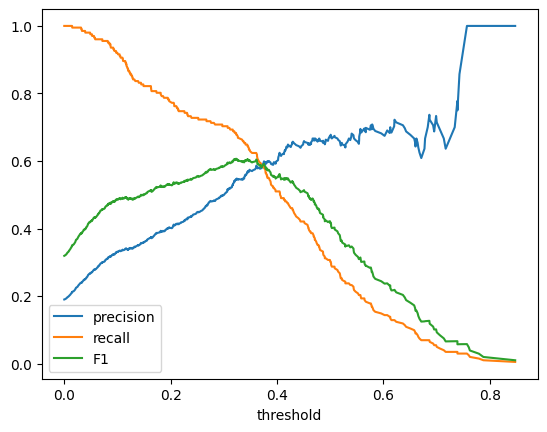

F1-optimal threshold: 0.323
precision=0.545, recall=0.683, F1=0.607


In [102]:
from sklearn.metrics import precision_recall_curve

y_val_prob = best_rf.predict_proba(X_val)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_val, y_val_prob)

f1 = 2 * precision * recall / (precision + recall + 1e-9)

plt.plot(thresholds, precision[:-1], label='precision')
plt.plot(thresholds, recall[:-1], label='recall')
plt.plot(thresholds, f1[:-1], label='F1')
plt.xlabel('threshold')
plt.legend()
plt.show()

best_idx = np.argmax(f1[:-1])
print(f'F1-optimal threshold: {thresholds[best_idx]:.3f}')
print(f'precision={precision[best_idx]:.3f}, recall={recall[best_idx]:.3f}, F1={f1[best_idx]:.3f}')

In [103]:
rows = []
for t in [0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5]:
    rows.append({'threshold': t, **evaluate(best_rf, X_val, y_val, threshold=t)})

pd.DataFrame(rows)[['threshold', 'precision', 'recall', 'f1']].round(3)

,threshold,precision,recall,f1
0,0.15,0.359,0.822,0.500
1,0.20,0.401,0.772,0.528
2,0.25,0.450,0.728,0.556
3,0.30,0.500,0.703,0.584
4,0.35,0.570,0.624,0.596
5,0.40,0.602,0.510,0.552
6,0.50,0.670,0.302,0.416


In [104]:
threshold = 0.32

In [105]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

test_results = []
for name, model in [('LogReg', lr), ('RandomForest', best_rf), ('XGBoost', xgb_final)]:
    # t = threshold if name == 'RandomForest' else 0.5
    t = threshold
    test_results.append({'model': name, 'threshold': t,
                         **evaluate(model, X_test, y_test, threshold=t)})

pd.DataFrame(test_results).round(3)

,model,threshold,roc_auc,pr_auc,precision,recall,f1
0,LogReg,0.32,0.818,0.483,0.462,0.564,0.508
1,RandomForest,0.32,0.866,0.618,0.531,0.644,0.582
2,XGBoost,0.32,0.855,0.573,0.553,0.594,0.573


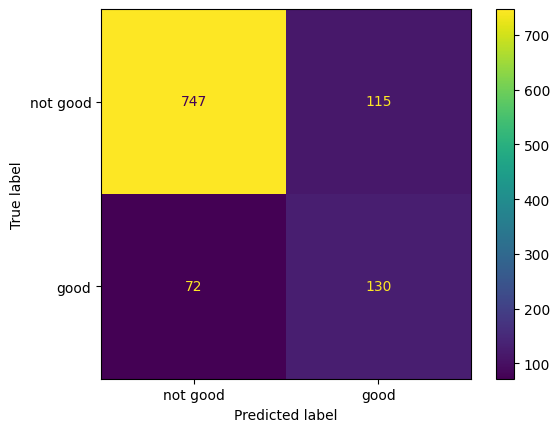

In [106]:
y_test_prob = best_rf.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= threshold).astype(int)

cm = confusion_matrix(y_test, y_test_pred)
ConfusionMatrixDisplay(cm, display_labels=['not good', 'good']).plot()
plt.show()

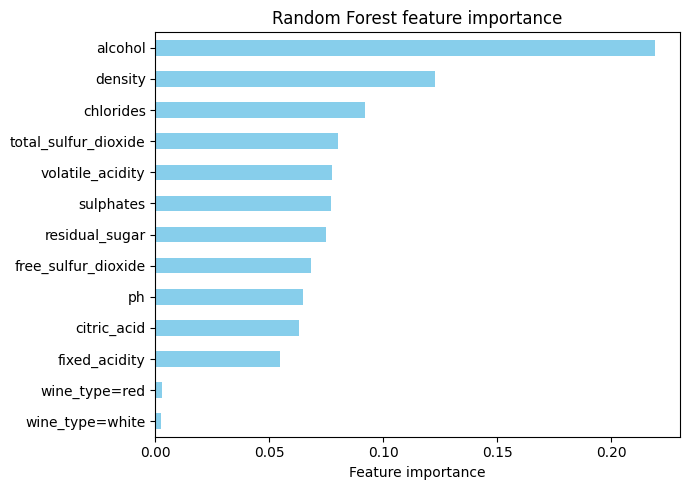

,0
alcohol,0.219
density,0.123
chlorides,0.092
total_sulfur_dioxide,0.080
volatile_acidity,0.077
sulphates,0.077
residual_sugar,0.075
free_sulfur_dioxide,0.068
ph,0.065
citric_acid,0.063


In [107]:
importances = best_rf.feature_importances_
feature_names = dv.get_feature_names_out()

imp = pd.Series(importances, index=feature_names).sort_values()

plt.figure(figsize=(7, 5))
imp.plot(kind='barh', color='skyblue')
plt.xlabel('Feature importance')
plt.title('Random Forest feature importance')
plt.tight_layout()
plt.show()

imp.sort_values(ascending=False).round(3)

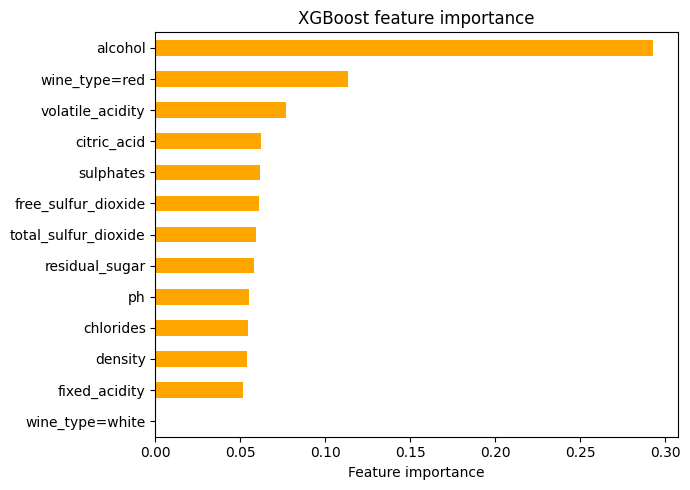

,0
alcohol,0.293
wine_type=red,0.113
volatile_acidity,0.077
citric_acid,0.062
sulphates,0.061
free_sulfur_dioxide,0.061
total_sulfur_dioxide,0.059
residual_sugar,0.058
ph,0.055
chlorides,0.054


In [108]:
xgb_imp = pd.Series(xgb_final.feature_importances_, index=feature_names).sort_values()

plt.figure(figsize=(7, 5))
xgb_imp.plot(kind='barh', color='orange')
plt.xlabel('Feature importance')
plt.title('XGBoost feature importance')
plt.tight_layout()
plt.show()

xgb_imp.sort_values(ascending=False).round(3)

# Selecting the best model

In [109]:
cv_table = pd.DataFrame(cv_rows).sort_values('pr_auc_mean', ascending=False)
print(cv_table.round(3))

best_name = cv_table.iloc[0]['model']
print(f'\nSelected model: {best_name} (highest cross-validated PR-AUC)')

          model  roc_auc_mean  roc_auc_std  pr_auc_mean  pr_auc_std
1  RandomForest         0.840        0.010        0.557       0.020
2       XGBoost         0.830        0.010        0.534       0.011
0        LogReg         0.834        0.004        0.529       0.024

Selected model: RandomForest (highest cross-validated PR-AUC)


In [110]:
final_params = grid_search.best_params_
print(final_params)
threshold = 0.32

y_full_train = df_full_train.good.values
full_train_dicts = df_full_train.drop(columns=['good', 'quality']).to_dict(orient='records')

dv_final = DictVectorizer(sparse=False)
X_full_train = dv_final.fit_transform(full_train_dicts)
X_test_final = dv_final.transform(test_dicts)

final_model = RandomForestClassifier(**final_params, random_state=42, n_jobs=-1)
final_model.fit(X_full_train, y_full_train)

{'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}


RandomForestClassifier(min_samples_leaf=5, n_estimators=200, n_jobs=-1,
                       random_state=42)

In [111]:
final_scores = evaluate(final_model, X_test_final, y_test, threshold=threshold)
pd.Series(final_scores).round(3)

,0
roc_auc,0.867
pr_auc,0.605
precision,0.529
recall,0.639
f1,0.578


In [112]:
output_file = 'model.bin'

with open(output_file, 'wb') as f_out:
    pickle.dump((dv_final, final_model, threshold), f_out)

print(f'Saved to {output_file}')

Saved to model.bin


Testing the model

In [113]:
with open(output_file, 'rb') as f_in:
    dv_loaded, model_loaded, threshold_loaded = pickle.load(f_in)

sample = df_test.iloc[5].to_dict()
X_sample = dv_loaded.transform([sample])
prob = model_loaded.predict_proba(X_sample)[0, 1]

print('Probability of good:', round(prob, 3))
print('Prediction:', 'good' if prob >= threshold_loaded else 'not good')
print('Actual:', 'good' if y_test[0] == 1 else 'not good')

Probability of good: 0.578
Prediction: good
Actual: good
